In [1]:
import torch
from torch import nn
import matplotlib.pyplot as plt

In [2]:
torch.__version__

'2.14.0+cu130'

In [3]:
device="cuda" if torch.cuda.is_available() else "cpu"
print(f"Using device {device}")

Using device cuda


In [4]:
weight=0.7
bias=0.3

X=torch.arange(0,1,0.02).unsqueeze(1)
Y=weight*X+bias

In [5]:
train_split=int(0.8*len(X))
X_train,Y_train=X[:train_split],Y[:train_split]
X_test,Y_test=X[train_split:],Y[train_split:]
X_train

tensor([[0.0000],
        [0.0200],
        [0.0400],
        [0.0600],
        [0.0800],
        [0.1000],
        [0.1200],
        [0.1400],
        [0.1600],
        [0.1800],
        [0.2000],
        [0.2200],
        [0.2400],
        [0.2600],
        [0.2800],
        [0.3000],
        [0.3200],
        [0.3400],
        [0.3600],
        [0.3800],
        [0.4000],
        [0.4200],
        [0.4400],
        [0.4600],
        [0.4800],
        [0.5000],
        [0.5200],
        [0.5400],
        [0.5600],
        [0.5800],
        [0.6000],
        [0.6200],
        [0.6400],
        [0.6600],
        [0.6800],
        [0.7000],
        [0.7200],
        [0.7400],
        [0.7600],
        [0.7800]])

In [6]:
len(X_train),len(Y_train),len(X_test),len(Y_test)

(40, 40, 10, 10)

In [7]:
def plot_prediction(train_data=X_train,train_label=Y_train,test_data=X_test,test_label=Y_test,predictions=None):
    plt.figure(figsize=(6,3))

    plt.scatter(train_data,train_label,color="blue",s=4,label="Training data")
    plt.scatter(test_data,test_label,color="red",s=4,label="Testing data")

    if predictions is not None:
        plt.scatter(test_label,predictions,color="Green",s=4,label="Prediction")
    plt.legend(prop={"size":14})

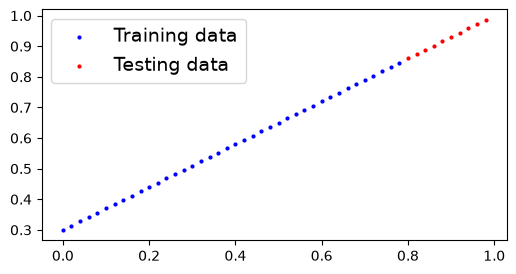

In [8]:
plot_prediction(X_train,Y_train,X_test,Y_test)

In [9]:
class LinearRegression(nn.Module):
    def __init__(self):
        super().__init__()   
        self.linear_layer=nn.Linear(in_features=1,out_features=1)
    def forward(self,x:torch.Tensor)->torch.Tensor:
        return self.linear_layer(x)
torch.manual_seed(42)
model=LinearRegression()
model,model.state_dict()

(LinearRegression(
   (linear_layer): Linear(in_features=1, out_features=1, bias=True)
 ),
 OrderedDict([('linear_layer.weight', tensor([[0.7645]])),
              ('linear_layer.bias', tensor([0.8300]))]))

In [10]:
device="cuda" if torch.cuda.is_available() else "cpu"

In [11]:
X_train[:5],Y_train[:5]

(tensor([[0.0000],
         [0.0200],
         [0.0400],
         [0.0600],
         [0.0800]]),
 tensor([[0.3000],
         [0.3140],
         [0.3280],
         [0.3420],
         [0.3560]]))

In [12]:
next(model.parameters()).device

device(type='cpu')

In [13]:
model.to(device)
next(model.parameters()).device

device(type='cuda', index=0)

In [14]:
model.state_dict()

OrderedDict([('linear_layer.weight', tensor([[0.7645]], device='cuda:0')),
             ('linear_layer.bias', tensor([0.8300], device='cuda:0'))])

In [15]:
loss_fn=nn.L1Loss()
optimizer=torch.optim.SGD(params=model.parameters(),lr=0.01)

In [16]:
torch.manual_seed(42)
epocs=200

X_train=X_train.to(device)
Y_train=Y_train.to(device)
X_test=X_test.to(device)
Y_test=Y_test.to(device)

for epoc in range(epocs):

    model.train()

    y_pred=model(X_train)

    loss=loss_fn(y_pred,Y_train)

    optimizer.zero_grad()

    loss.backward()

    optimizer.step()

    model.eval()

    with torch.inference_mode():
        test_pred=model(X_test)

        test_loss=loss_fn(test_pred,Y_test)

    if epoc%10==0:
        print(f"Epoc: {epoc} | Loss: {loss} | Test loss: {test_loss}")

Epoc: 0 | Loss: 0.5551779270172119 | Test loss: 0.5739762187004089
Epoc: 10 | Loss: 0.4399681091308594 | Test loss: 0.4392664134502411
Epoc: 20 | Loss: 0.3247582018375397 | Test loss: 0.30455657839775085
Epoc: 30 | Loss: 0.20954833924770355 | Test loss: 0.16984669864177704
Epoc: 40 | Loss: 0.09433844685554504 | Test loss: 0.03513690456748009
Epoc: 50 | Loss: 0.023886388167738914 | Test loss: 0.04784907028079033
Epoc: 60 | Loss: 0.019956795498728752 | Test loss: 0.045803118497133255
Epoc: 70 | Loss: 0.016517987474799156 | Test loss: 0.037530567497015
Epoc: 80 | Loss: 0.013089174404740334 | Test loss: 0.02994490973651409
Epoc: 90 | Loss: 0.009653178043663502 | Test loss: 0.02167237363755703
Epoc: 100 | Loss: 0.006215683650225401 | Test loss: 0.014086711220443249
Epoc: 110 | Loss: 0.00278724217787385 | Test loss: 0.005814164876937866
Epoc: 120 | Loss: 0.0012645035749301314 | Test loss: 0.013801801018416882
Epoc: 130 | Loss: 0.0012645035749301314 | Test loss: 0.013801801018416882
Epoc: 140

In [17]:
model.state_dict()

OrderedDict([('linear_layer.weight', tensor([[0.6968]], device='cuda:0')),
             ('linear_layer.bias', tensor([0.3025], device='cuda:0'))])

In [18]:
weight,bias

(0.7, 0.3)

In [19]:
model.eval()
with torch.inference_mode():
    y_preds=model(X_test)
y_preds

tensor([[0.8600],
        [0.8739],
        [0.8878],
        [0.9018],
        [0.9157],
        [0.9296],
        [0.9436],
        [0.9575],
        [0.9714],
        [0.9854]], device='cuda:0')

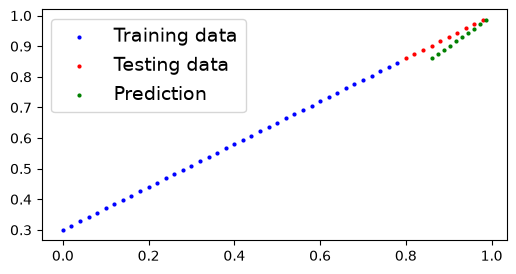

In [20]:
plot_prediction(predictions=y_preds.cpu())

In [21]:
from pathlib import Path

MODEL_PATH=Path("model")
MODEL_PATH.mkdir(parents=True,exist_ok=True)

MODEL_NAME="01_saved_model.pth"
MODEL_SAVE_PATH=MODEL_PATH/MODEL_NAME

MODEL_SAVE_PATH

PosixPath('model/01_saved_model.pth')

In [22]:
torch.save(obj=model.state_dict(),f=MODEL_SAVE_PATH)

In [23]:
model.state_dict()

OrderedDict([('linear_layer.weight', tensor([[0.6968]], device='cuda:0')),
             ('linear_layer.bias', tensor([0.3025], device='cuda:0'))])

In [24]:
load_model=LinearRegression()

load_model.load_state_dict(torch.load(MODEL_SAVE_PATH))

<All keys matched successfully>

In [25]:
load_model.to(device)

LinearRegression(
  (linear_layer): Linear(in_features=1, out_features=1, bias=True)
)

In [26]:
next(load_model.parameters()).device

device(type='cuda', index=0)

In [27]:
load_model.state_dict()

OrderedDict([('linear_layer.weight', tensor([[0.6968]], device='cuda:0')),
             ('linear_layer.bias', tensor([0.3025], device='cuda:0'))])

In [28]:
load_model.eval()
with torch.inference_mode():
    loaded_test_pred=load_model(X_test)
y_preds==loaded_test_pred

tensor([[True],
        [True],
        [True],
        [True],
        [True],
        [True],
        [True],
        [True],
        [True],
        [True]], device='cuda:0')